# Kelly portfolio construction with denoising, detoning and HRP

*Group project, MScFE 652 Portfolio Management, WorldQuant University (2026).*

**Machine-learning enhancements to Kelly-based portfolio construction: denoising, hierarchical clustering (HRP), detoning and leakage-aware backtesting.**

Universe (10 assets): AAPL, MSFT, GOOGL, AMZN, NVDA, META, JPM, JNJ, V, XOM.
Training window: 2024-01-01 to 2025-09-30 (in-sample). Test window: 2025-10-01 to 2025-12-31 (out-of-sample).

The notebook follows the project steps in order:

- Step 1: optimal Kelly portfolio, with and without a 20% concentration cap;
- Step 2: out-of-sample comparison of Half-Kelly, Kelly and Double-Kelly on Q4 2025;
- Step 3: backtesting with purged K-fold cross-validation, CPCV and the Deflated Sharpe Ratio;
- Steps 4 and 5: denoising (Marchenko-Pastur), detoning and Hierarchical Risk Parity applied to the same portfolio;
- Step 6: whether combined improvements beat single ones out of sample.

## 0. Setup and data

Prices are **daily dividend- and split-adjusted closes from Yahoo Finance**. When the notebook
runs on a networked machine (Google Colab, for instance) the cell below downloads them with
`yfinance`. Otherwise it falls back on `data/prices_real.csv`, the snapshot shipped with this
repository, which is the same data downloaded on 2026-08-28. We use simple (arithmetic) daily
returns throughout, so a portfolio return is just the weighted sum of asset returns.
Annualisation uses 252 days. The risk-free rate is a flat 4% p.a., a proxy for the 3-month
T-bill over the sample.

In [1]:
from __future__ import annotations
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from itertools import combinations
from pathlib import Path
from scipy.optimize import minimize
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
from scipy.stats import norm, skew, kurtosis

OUT = Path("figures"); OUT.mkdir(exist_ok=True)
TICKERS = ["AAPL","MSFT","GOOGL","AMZN","NVDA","META","JPM","JNJ","V","XOM"]
TRAIN_START, TRAIN_END = "2024-01-01", "2025-09-30"
TEST_START,  TEST_END  = "2025-10-01", "2025-12-31"
RF_ANNUAL = 0.04           # 3-month T-bill proxy over the sample (approx.)
TD = 252                   # trading days per year
RF_D = RF_ANNUAL / TD

# Okabe-Ito colorblind-safe categorical palette (fixed order, never cycled)
PAL = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#CC79A7"]
plt.rcParams.update({
    "figure.dpi": 150, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
})

In [2]:
from IPython.display import display, Image

In [3]:
TICKERS = ["AAPL","MSFT","GOOGL","AMZN","NVDA","META","JPM","JNJ","V","XOM"]
TRAIN_START, TRAIN_END = "2024-01-01", "2025-09-30"
TEST_START,  TEST_END  = "2025-10-01", "2025-12-31"

def load_prices():
    """Yahoo Finance if the network allows it, else the shipped CSV snapshot."""
    try:
        import yfinance as yf
        px = yf.download(TICKERS, start=TRAIN_START, end="2026-01-01",
                         auto_adjust=True, progress=False)["Close"].dropna(how="all")
        assert px.shape[0] > 400
        print("[data] downloaded from Yahoo Finance:", px.shape)
        return px[TICKERS]
    except Exception as e:
        print(f"[data] yfinance unavailable ({e}); using the snapshot data/prices_real.csv")
        return pd.read_csv("data/prices_real.csv", index_col=0, parse_dates=True)[TICKERS]

px = load_prices()
rets = px.pct_change().dropna()          # simple daily returns
train = rets.loc[TRAIN_START:TRAIN_END]
test  = rets.loc[TEST_START:TEST_END]
print(f"{px.shape[0]} sessions | train {train.shape} | test {test.shape}")

[data] yfinance unavailable (); using the snapshot data/prices_real.csv
502 sessions | train (437, 10) | test (64, 10)


## Step 1: Optimal Kelly portfolio

The continuous-time Kelly rule (Thorp, 2006) maximises expected log-wealth. With the excess
return vector $\mu - r_f$ and covariance $\Sigma$, both annualised, the unconstrained solution
is $w^* = \Sigma^{-1}(\mu - r_f)$. Total exposure $\sum_i w_i$ comes out of the rule rather
than being imposed on it; whatever is left over is cash, or borrowing, at $r_f$. Since
$\Sigma^{-1}$ amplifies estimation noise, the unconstrained solution tends to be extreme.

To impose the concentration limit (no asset above 20% of the portfolio) we maximise the
quadratic approximation of expected log-growth, $w'(\mu-r_f) - \tfrac12 w'\Sigma w$, subject
to $\sum w_i = 1$ and $0 \le w_i \le 0.20$, so long-only and fully invested, and solve it with
SLSQP. The feasible set is a non-empty compact polytope and the objective is strictly concave,
so a solution exists and it is unique.

In [4]:
def kelly_unconstrained(mu: np.ndarray, cov: np.ndarray) -> np.ndarray:
    """Continuous-time Kelly (Thorp 2006): w* = Sigma^-1 (mu - rf).
    Total exposure sum(w) is an OUTPUT; residual is cash/leverage at rf."""
    return np.linalg.solve(cov, mu - RF_ANNUAL)

def kelly_capped(mu: np.ndarray, cov: np.ndarray, cap: float = 0.20) -> np.ndarray:
    """Max  w'(mu-rf) - 0.5 w'Sigma w  s.t. sum(w)=1, 0 <= w_i <= cap  (SLSQP)."""
    n = len(mu)
    def neg_obj(w): return -(w @ (mu - RF_ANNUAL) - 0.5 * w @ cov @ w)
    res = minimize(neg_obj, np.ones(n)/n, method="SLSQP",
                   bounds=[(0.0, cap)]*n,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1.0}],
                   options={"maxiter": 1000, "ftol": 1e-12})
    assert res.success, res.message
    return res.x

def moments(returns: pd.DataFrame):
    """Annualised arithmetic mean vector and covariance matrix."""
    return returns.mean().values * TD, returns.cov().values * TD

In [5]:
mu, cov = moments(train)
w_full = kelly_unconstrained(mu, cov)
w_cap  = kelly_capped(mu, cov)
step1 = pd.DataFrame({"Kelly unconstrained": w_full, "Kelly 20% cap": w_cap}, index=TICKERS)
step1.loc["TOTAL"] = step1.sum()
step1.round(4)

,Kelly unconstrained,Kelly 20% cap
AAPL,-0.5206,0.0
MSFT,-3.3096,0.0
GOOGL,2.6564,0.2
AMZN,-3.5772,0.2
NVDA,3.6296,0.2
META,3.1100,0.2
JPM,5.4903,0.2
JNJ,6.3120,0.0
V,-2.3969,0.0
XOM,-1.1678,0.0


## Step 2: Out of sample, Half-Kelly vs Kelly vs Double-Kelly

The capped Kelly weights from Step 1 are scaled by 0.5, 1.0 and 2.0. Uninvested capital earns
$r_f$ and Double-Kelly borrows 100% of equity at $r_f$. Metrics are computed on the 64 trading
days of Q4 2025. One thing to keep in mind when reading the table: with cash remunerated at
$r_f$, the *excess* return scales exactly linearly with the Kelly fraction, so the Sharpe ratio
is the same for the three portfolios by construction. Leverage changes the size of returns,
drawdowns and tail losses, not their risk-adjusted quality.

In [6]:
def portfolio_series(weights: np.ndarray, returns: pd.DataFrame) -> pd.Series:
    """Daily portfolio simple returns; cash residual (or borrowing) at rf."""
    invested = weights.sum()
    daily = returns.values @ weights + (1.0 - invested) * RF_D
    return pd.Series(daily, index=returns.index)

def metrics(daily: pd.Series) -> dict:
    r = daily.dropna()
    ann_ret = r.mean() * TD                       # arithmetic annualisation
    ann_vol = r.std(ddof=1) * np.sqrt(TD)
    sharpe = (ann_ret - RF_ANNUAL) / ann_vol if ann_vol > 0 else np.nan
    downside = r[r < RF_D].std(ddof=1) * np.sqrt(TD)
    sortino = (ann_ret - RF_ANNUAL) / downside if downside > 0 else np.nan
    wealth = (1 + r).cumprod()
    mdd = float((wealth / wealth.cummax() - 1).min())
    cvar95 = float(r[r <= r.quantile(0.05)].mean())
    return dict(cum_return=float((1 + r).prod() - 1), ann_return=float(ann_ret),
                ann_vol=float(ann_vol), sharpe=float(sharpe),
                sortino=float(sortino), max_drawdown=mdd, cvar95=cvar95)

def sr_daily(daily: pd.Series) -> float:
    r = daily.dropna()
    return float((r.mean() - RF_D) / r.std(ddof=1)) if r.std(ddof=1) > 0 else np.nan

def deflated_sharpe_ratio(sr_best_d: float, var_sr_d: float, n_trials: int,
                          T: int, skew_r: float, kurt_r: float) -> tuple[float, float]:
    """Bailey & Lopez de Prado (2014). ALL Sharpe quantities at DAILY frequency,
    T = number of daily observations. Returns (DSR, SR0_daily)."""
    if var_sr_d <= 0 or n_trials < 2:
        return np.nan, np.nan
    g = 0.5772156649015329                          # Euler-Mascheroni
    sr0 = np.sqrt(var_sr_d) * ((1 - g) * norm.ppf(1 - 1/n_trials)
                               + g * norm.ppf(1 - 1/(n_trials * np.e)))
    denom = np.sqrt(1 - skew_r * sr_best_d + (kurt_r - 1)/4 * sr_best_d**2)
    dsr = norm.cdf((sr_best_d - sr0) * np.sqrt(T - 1) / denom)
    return float(dsr), float(sr0)

In [7]:
def fig_wealth(series: dict, path: Path, title: str):
    fig, ax = plt.subplots(figsize=(7.6, 3.9))
    for i, (name, s) in enumerate(series.items()):
        w = (1 + s).cumprod()
        ax.plot(w.index, w.values, lw=1.8, color=PAL[i % len(PAL)], label=name)
        ax.annotate(f" {w.iloc[-1]:.3f}", xy=(w.index[-1], w.iloc[-1]),
                    color=PAL[i % len(PAL)], fontsize=8, va="center")
    ax.set_ylabel("Wealth (base = 1)")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)
    fig.autofmt_xdate()
    fig.tight_layout(); fig.savefig(path); plt.close(fig)

def fig_weights(variants: dict, path: Path):
    fig, ax = plt.subplots(figsize=(8.2, 3.9))
    x = np.arange(len(TICKERS)); width = 0.14
    for i, (name, w) in enumerate(variants.items()):
        ax.bar(x + i*width, w, width*0.92, color=PAL[i % len(PAL)], label=name)
    ax.set_xticks(x + width*(len(variants)-1)/2)
    ax.set_xticklabels(TICKERS)
    ax.set_ylabel("Weight")
    ax.set_title("Training-window weights, baseline vs ML-enhanced allocations")
    ax.legend(frameon=False, fontsize=7, ncol=2)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)

def fig_eigen(evals: np.ndarray, q: float, var_fit: float, lambda_plus: float, path: Path):
    fig, ax = plt.subplots(figsize=(6.6, 3.6))
    ax.hist(evals, bins=30, density=True, alpha=0.55, color=PAL[0],
            edgecolor="white", label="Empirical eigenvalues")
    x, pdf = mp_pdf(var_fit, q, 600)
    ax.plot(x, pdf, lw=2, color=PAL[3], label=f"Marchenko-Pastur fit (q={q:.0f})")
    ax.axvline(lambda_plus, color=PAL[1], lw=1.5, ls="--",
               label=f"Noise edge $\\lambda_+$ = {lambda_plus:.2f}")
    ax.set_xlabel("Eigenvalue"); ax.set_ylabel("Density")
    ax.set_title("Eigenvalue spectrum of the training correlation matrix")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)

def fig_cpcv(sharpes: np.ndarray, dsr: float, path: Path):
    fig, ax = plt.subplots(figsize=(6.8, 3.6))
    ax.hist(sharpes, bins=12, alpha=0.75, color=PAL[0], edgecolor="white")
    med = np.nanmedian(sharpes)
    ax.axvline(med, color=PAL[3], lw=2, label=f"Median SR = {med:.2f}")
    ax.axvline(0, color="grey", lw=1, ls="--")
    ax.set_xlabel("Annualised Sharpe ratio per CPCV path"); ax.set_ylabel("Paths")
    ax.set_title(f"CPCV(6,2): {len(sharpes)} backtest paths — DSR = {dsr:.1%}")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)

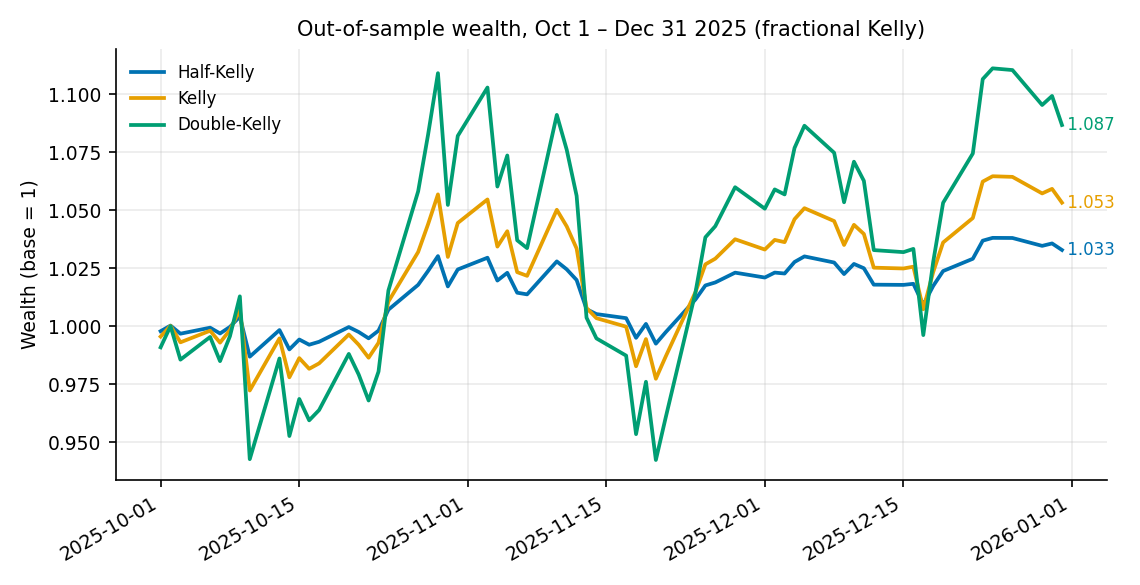

,cum_return,ann_return,ann_vol,sharpe,sortino,max_drawdown,cvar95
Half-Kelly,0.0329,0.1324,0.1018,0.9083,1.3633,-0.0367,-0.0129
Kelly,0.0533,0.2249,0.2035,0.9083,1.3633,-0.0752,-0.0261
Double-Kelly,0.0868,0.4097,0.4070,0.9083,1.3633,-0.1504,-0.0523


In [8]:
ports  = {"Half-Kelly": 0.5*w_cap, "Kelly": w_cap, "Double-Kelly": 2.0*w_cap}
series = {n: portfolio_series(w, test) for n, w in ports.items()}
step2  = pd.DataFrame({n: metrics(s) for n, s in series.items()}).T
fig_wealth(series, OUT / "fig1_step2_wealth.png",
           "Out-of-sample wealth, Oct 1 – Dec 31 2025 (fractional Kelly)")
display(Image(str(OUT / "fig1_step2_wealth.png")))
step2.round(4)

## Step 3: Backtesting with K-fold cross-validation

**Why a single split or vanilla K-fold is not enough.** A single train/test split gives one
point estimate of out-of-sample performance, and its variance is often larger than the effect
we are trying to measure. Standard K-fold shuffles or reuses observations that are *serially
correlated* with the test set, so information leaks across the train/test boundary and the
estimated Sharpe is biased upward. Walk-forward only tests one historical path.

**Procedure: purged K-fold with embargo (Lopez de Prado 2018, ch. 7).** The two years
(502 sessions) are split chronologically into $k=5$ contiguous folds. For each fold $i$, fold
$i$ is the test set. The training set is every remaining day *minus* the 5 days just before the
test block (purge) and the 5 days just after it (embargo). We re-estimate $\mu, \Sigma$ on that
training set, solve Kelly (unconstrained and capped) and evaluate on fold $i$. Metrics are then
averaged across folds.

**CPCV.** Combinatorial Purged CV (ch. 12) partitions the sample into $N=6$ groups and holds
out every pair of groups ($k=2$). That gives $\binom{6}{2}=15$ purged backtest paths, so a
*distribution* of Sharpe ratios rather than a single number.

**Deflated Sharpe Ratio (Bailey and Lopez de Prado, 2014).** The DSR is the probability that
the true Sharpe exceeds zero, given that we are reporting the *best* of $N$ trials:
$DSR = \Phi\big[(\widehat{SR} - SR_0)\sqrt{T-1} / \sqrt{1 - \gamma_3 \widehat{SR} + \tfrac{\gamma_4 - 1}{4}\widehat{SR}^2}\big]$,
where $SR_0$ is the expected maximum Sharpe of $N$ unskilled strategies. Every Sharpe quantity
enters at the **daily** frequency, to match $T$, the number of daily observations.

In [9]:
def purged_train_idx(n: int, test_idx: np.ndarray, embargo: int = 5) -> np.ndarray:
    train = np.ones(n, dtype=bool)
    train[test_idx] = False
    lo, hi = test_idx.min(), test_idx.max()
    train[max(0, lo - embargo):lo] = False           # purge before the block
    train[hi + 1:min(n, hi + 1 + embargo)] = False   # embargo after the block
    return np.where(train)[0]

def purged_train_idx_multi(n: int, blocks: list[np.ndarray], embargo: int = 5) -> np.ndarray:
    train = np.ones(n, dtype=bool)
    for b in blocks:
        train[b] = False
        lo, hi = b.min(), b.max()
        train[max(0, lo - embargo):lo] = False
        train[hi + 1:min(n, hi + 1 + embargo)] = False
    return np.where(train)[0]

def purged_kfold(returns: pd.DataFrame, k: int = 5, embargo: int = 5) -> pd.DataFrame:
    n = len(returns)
    edges = np.linspace(0, n, k + 1, dtype=int)
    rows = []
    for i in range(k):
        te = np.arange(edges[i], edges[i+1])
        tr = purged_train_idx(n, te, embargo)
        mu, cov = moments(returns.iloc[tr])
        w_full = kelly_unconstrained(mu, cov)
        w_cap  = kelly_capped(mu, cov)
        for name, w in [("Kelly unconstrained", w_full),
                        ("Kelly 20% cap", w_cap),
                        ("Half-Kelly (cap)", 0.5 * w_cap),
                        ("Double-Kelly (cap)", 2.0 * w_cap)]:
            m = metrics(portfolio_series(w, returns.iloc[te]))
            m["fold"], m["strategy"] = i + 1, name
            rows.append(m)
    df = pd.DataFrame(rows)
    per_fold = df.pivot(index="fold", columns="strategy", values="sharpe")
    mean_tbl = df.groupby("strategy")[
        ["cum_return","ann_return","ann_vol","sharpe","sortino","max_drawdown","cvar95"]
    ].mean()
    return mean_tbl, per_fold

def cpcv(returns: pd.DataFrame, N: int = 6, k: int = 2, embargo: int = 5) -> dict:
    n = len(returns)
    edges = np.linspace(0, n, N + 1, dtype=int)
    groups = [np.arange(edges[i], edges[i+1]) for i in range(N)]
    stats, best = [], (-np.inf, None)
    for combo in combinations(range(N), k):
        blocks = [groups[i] for i in combo]
        te = np.concatenate(blocks)
        tr = purged_train_idx_multi(n, blocks, embargo)
        mu, cov = moments(returns.iloc[tr])
        w = kelly_capped(mu, cov)
        s = portfolio_series(w, returns.iloc[te])
        m = metrics(s)
        srd = sr_daily(s)
        stats.append(dict(combo=combo, sharpe_ann=m["sharpe"], sr_daily=srd,
                          cum_return=m["cum_return"]))
        if srd > best[0]:
            best = (srd, s)
    sr_ann = np.array([x["sharpe_ann"] for x in stats])
    sr_d = np.array([x["sr_daily"] for x in stats])
    r_best = best[1].dropna()
    dsr, sr0_d = deflated_sharpe_ratio(
        sr_best_d=float(np.nanmax(sr_d)),
        var_sr_d=float(np.nanvar(sr_d, ddof=1)),
        n_trials=len(sr_d), T=len(r_best),
        skew_r=float(skew(r_best)), kurt_r=float(kurtosis(r_best, fisher=False)))
    return dict(n_paths=len(sr_ann),
                sharpe_mean=float(np.nanmean(sr_ann)),
                sharpe_std=float(np.nanstd(sr_ann, ddof=1)),
                sharpe_p05=float(np.nanpercentile(sr_ann, 5)),
                sharpe_p50=float(np.nanpercentile(sr_ann, 50)),
                sharpe_p95=float(np.nanpercentile(sr_ann, 95)),
                sharpe_max=float(np.nanmax(sr_ann)),
                sr_daily_max=float(np.nanmax(sr_d)), sr0_daily=sr0_d,
                dsr=dsr, all_sharpes=sr_ann)

In [10]:
step3, per_fold = purged_kfold(rets, k=5, embargo=5)
print("Per-fold Sharpe ratios:")
display(per_fold.round(2))
step3.round(4)

Per-fold Sharpe ratios:


strategy,Double-Kelly (cap),Half-Kelly (cap),Kelly 20% cap,Kelly unconstrained
fold,,,,
1,3.90,3.90,3.90,2.21
2,1.24,1.24,1.24,1.32
3,-0.08,-0.08,-0.08,-0.66
4,1.64,1.64,1.64,0.53
5,-0.10,-0.10,-0.10,0.48


,cum_return,ann_return,ann_vol,sharpe,sortino,max_drawdown,cvar95
strategy,,,,,,,
Double-Kelly (cap),0.2627,0.6409,0.4656,1.3201,2.1023,-0.2546,-0.0669
Half-Kelly (cap),0.0771,0.1902,0.1164,1.3201,2.1023,-0.0676,-0.0166
Kelly 20% cap,0.1388,0.3405,0.2328,1.3201,2.1023,-0.1336,-0.0334
Kelly unconstrained,-0.0864,1.8975,2.8517,0.7760,1.1036,-0.8429,-0.4346


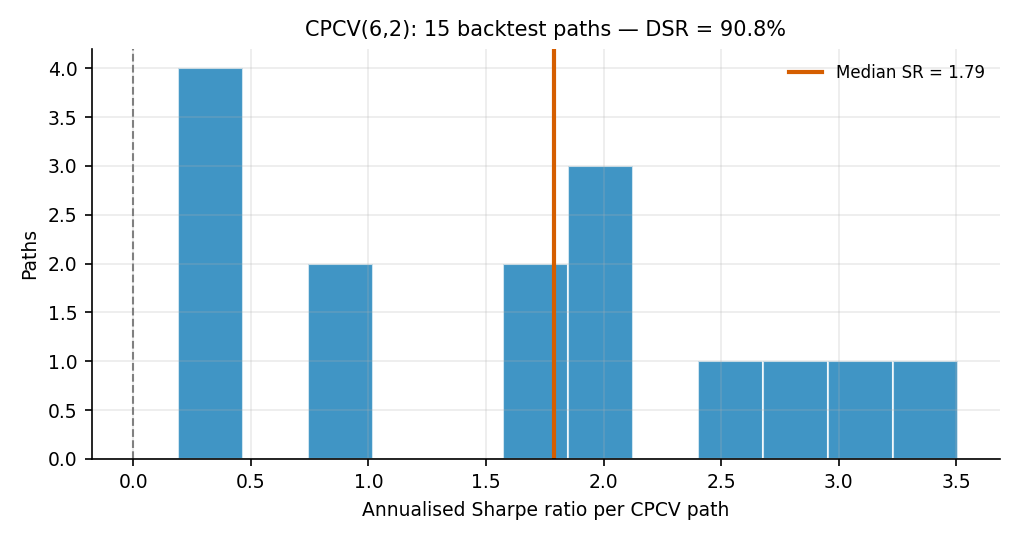

n_paths         15.0000
sharpe_mean      1.6384
sharpe_std       1.1035
sharpe_p05       0.2405
sharpe_p50       1.7914
sharpe_p95       3.1594
sharpe_max       3.5093
sr_daily_max     0.2211
sr0_daily        0.1231
dsr              0.9084
dtype: float64

In [11]:
cp = cpcv(rets, N=6, k=2, embargo=5)
fig_cpcv(cp["all_sharpes"], cp["dsr"], OUT / "fig2_step3_cpcv.png")
display(Image(str(OUT / "fig2_step3_cpcv.png")))
pd.Series({k: v for k, v in cp.items() if k != "all_sharpes"}).round(4)

## Steps 4 and 5: Denoising, detoning and Hierarchical Risk Parity

**Denoising (Marchenko-Pastur).** With $T$ observations of $N$ assets, even a pure-noise
correlation matrix has dispersed eigenvalues, bounded above by
$\lambda_+ = \sigma^2(1 + \sqrt{1/q})^2$ with $q = T/N$. Empirical eigenvalues above
$\lambda_+$ carry signal. The bulk below is noise and gets replaced by its average (the
constant-residual method). With only $N=10$ eigenvalues, fitting $\sigma^2$ on a histogram is
unreliable, so $\sigma^2$ is obtained as the fixed point of "$\sigma^2$ equals the mean of the
noise eigenvalues".

**Detoning.** The top eigenvector is the market factor. Setting $\lambda_1 = 0$ and
renormalising the diagonal leaves the idiosyncratic correlation structure, which is what an
active allocation should be looking at.

**HRP (Lopez de Prado, 2016).** Cluster the assets on the correlation distance
$d_{ij} = \sqrt{(1-\rho_{ij})/2}$ with single linkage, quasi-diagonalise, then allocate by
recursive bisection with inverse-variance splits. No matrix is inverted at any point.

In [12]:
def mp_pdf(var: float, q: float, pts: int = 1000):
    lmin = var * (1 - np.sqrt(1/q))**2
    lmax = var * (1 + np.sqrt(1/q))**2
    x = np.linspace(lmin, lmax, pts)
    pdf = q / (2*np.pi*var*x) * np.sqrt(np.maximum((lmax - x)*(x - lmin), 0))
    return x, pdf

def fit_mp_var(evals: np.ndarray, q: float) -> tuple[float, float, int]:
    """Fixed-point fit of the noise variance sigma^2. A histogram fit is
    meaningless with only N = 10 eigenvalues, so we use the self-consistent
    property E[noise eigenvalue] = sigma^2: start at sigma^2 = 1, compute
    lambda_+, classify eigenvalues, reset sigma^2 to the mean of the noise
    bulk, iterate to convergence."""
    evals = np.sort(evals)[::-1]
    var = 1.0
    for _ in range(100):
        lambda_plus = var * (1 + np.sqrt(1/q))**2
        n_signal = max(int((evals > lambda_plus).sum()), 1)
        new_var = evals[n_signal:].mean() if n_signal < len(evals) else var
        if abs(new_var - var) < 1e-12:
            break
        var = new_var
    return var, lambda_plus, n_signal

def denoise_corr(corr: np.ndarray, q: float):
    evals, evecs = np.linalg.eigh(corr)
    order = np.argsort(evals)[::-1]
    evals, evecs = evals[order], evecs[:, order]
    var, lambda_plus, n_signal = fit_mp_var(evals, q)
    new = evals.copy()
    new[n_signal:] = new[n_signal:].mean()          # constant residual method
    c = evecs @ np.diag(new) @ evecs.T
    d = np.sqrt(np.diag(c))
    return c / np.outer(d, d), n_signal, lambda_plus, evals

def detone(corr: np.ndarray, n_market: int = 1) -> np.ndarray:
    evals, evecs = np.linalg.eigh(corr)
    order = np.argsort(evals)[::-1]
    evals, evecs = evals[order], evecs[:, order]
    evals[:n_market] = 0.0
    c = evecs @ np.diag(evals) @ evecs.T
    d = np.sqrt(np.diag(c)); d[d == 0] = 1.0
    return c / np.outer(d, d)

In [13]:
def hrp_weights(cov: pd.DataFrame, corr: pd.DataFrame | None = None) -> pd.Series:
    if corr is None:
        d = np.sqrt(np.diag(cov.values))
        corr = pd.DataFrame(cov.values / np.outer(d, d),
                            index=cov.index, columns=cov.columns)
    dist = np.sqrt(0.5 * np.clip(1 - corr.values, 0, 2))
    link = linkage(squareform(dist, checks=False), method="single")
    order = _quasi_diag(link)
    ordered = [corr.index[i] for i in order]
    w = _recursive_bisect(cov, ordered)
    return w.reindex(cov.index).fillna(0.0)

def _quasi_diag(link):
    link = link.astype(int)
    sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
    n_items = link[-1, 3]
    while sort_ix.max() >= n_items:
        sort_ix.index = range(0, sort_ix.shape[0]*2, 2)
        df0 = sort_ix[sort_ix >= n_items]
        i, j = df0.index, df0.values - n_items
        sort_ix[i] = link[j, 0]
        sort_ix = pd.concat([sort_ix, pd.Series(link[j, 1], index=i+1)]).sort_index()
        sort_ix.index = range(sort_ix.shape[0])
    return sort_ix.tolist()

def _ivp(cov_):
    iv = 1.0 / np.diag(cov_)
    return iv / iv.sum()

def _cluster_var(cov, items):
    c = cov.loc[items, items].values
    w = _ivp(c).reshape(-1, 1)
    return float((w.T @ c @ w).squeeze())

def _recursive_bisect(cov, ordered):
    w = pd.Series(1.0, index=ordered)
    clusters = [ordered]
    while clusters:
        clusters = [c[j:k] for c in clusters
                    for j, k in ((0, len(c)//2), (len(c)//2, len(c))) if len(c) > 1]
        for i in range(0, len(clusters), 2):
            c0, c1 = clusters[i], clusters[i+1]
            v0, v1 = _cluster_var(cov, c0), _cluster_var(cov, c1)
            alpha = 1 - v0 / (v0 + v1)
            w.loc[c0] *= alpha
            w.loc[c1] *= 1 - alpha
    return w

In [14]:
def build_variants(train: pd.DataFrame):
    mu, cov = moments(train)
    corr = train.corr().values
    vol = np.sqrt(np.diag(cov))
    q = train.shape[0] / train.shape[1]
    corr_dn, n_signal, lambda_plus, evals = denoise_corr(corr, q)
    corr_dt = detone(corr_dn, 1)
    cov_dn = np.outer(vol, vol) * corr_dn
    cov_dt = np.outer(vol, vol) * corr_dt
    cov_df    = pd.DataFrame(cov,    index=TICKERS, columns=TICKERS)
    cov_dn_df = pd.DataFrame(cov_dn, index=TICKERS, columns=TICKERS)
    cov_dt_df = pd.DataFrame(cov_dt, index=TICKERS, columns=TICKERS)
    corr_dn_df = pd.DataFrame(corr_dn, index=TICKERS, columns=TICKERS)
    corr_dt_df = pd.DataFrame(corr_dt, index=TICKERS, columns=TICKERS)
    variants = {
        "Kelly (baseline, 20% cap)":   kelly_capped(mu, cov),
        "Kelly + denoising":           kelly_capped(mu, cov_dn),
        "Kelly + denoising + detoning": kelly_capped(mu, cov_dt),
        "HRP (clustering only)":       hrp_weights(cov_df).values,
        "HRP + denoising":             hrp_weights(cov_dn_df, corr_dn_df).values,
        "HRP + denoising + detoning":  hrp_weights(cov_dt_df, corr_dt_df).values,
    }
    diag = dict(q=q, n_signal=int(n_signal), lambda_plus=float(lambda_plus),
                evals=evals, top_eig_share=float(evals[0] / evals.sum()),
                cond_raw=float(np.linalg.cond(corr)),
                cond_dn=float(np.linalg.cond(corr_dn)),
                gross_kelly_raw=float(np.abs(kelly_unconstrained(mu, cov)).sum()),
                gross_kelly_dn=float(np.abs(kelly_unconstrained(mu, cov_dn)).sum()),
                gross_kelly_dt=float(np.abs(np.linalg.lstsq(cov_dt, mu - RF_ANNUAL,
                                                            rcond=None)[0]).sum()))
    return variants, diag

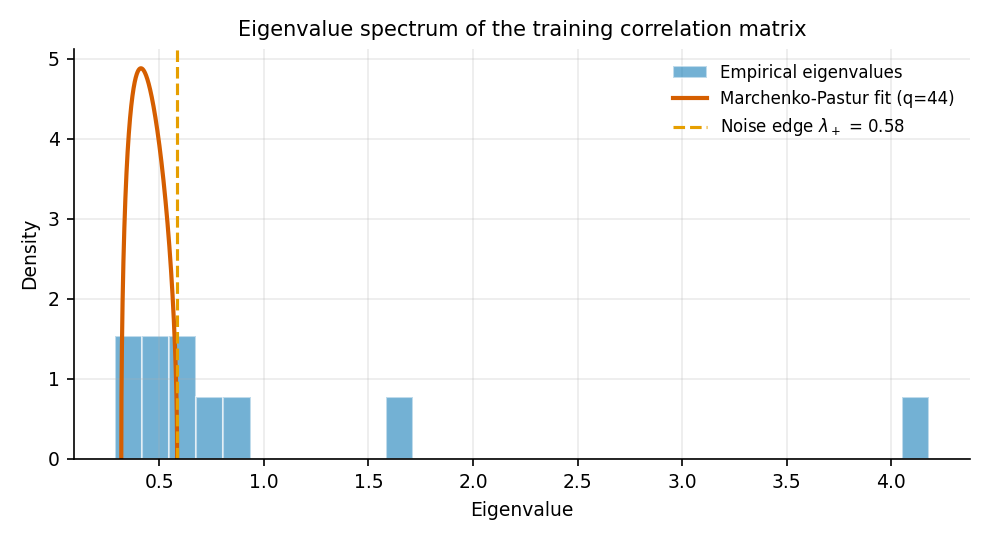

q = 43.7 | signal eigenvalues: 4 | lambda_+ = 0.585
top eigenvalue share of total variance: 41.8%
condition number of corr: raw 14.6 -> denoised 10.2
gross exposure of UNconstrained Kelly: raw 32.2x | denoised 26.1x | detoned 35.5x


In [15]:
variants, diag = build_variants(train)
var_fit, _, _ = fit_mp_var(diag["evals"], diag["q"])
fig_eigen(diag["evals"], diag["q"], var_fit, diag["lambda_plus"], OUT / "fig3_step4_eigen.png")
display(Image(str(OUT / "fig3_step4_eigen.png")))
print(f"q = {diag['q']:.1f} | signal eigenvalues: {diag['n_signal']} | lambda_+ = {diag['lambda_plus']:.3f}")
print(f"top eigenvalue share of total variance: {diag['top_eig_share']:.1%}")
print(f"condition number of corr: raw {diag['cond_raw']:.1f} -> denoised {diag['cond_dn']:.1f}")
print("gross exposure of UNconstrained Kelly:",
      f"raw {diag['gross_kelly_raw']:.1f}x | denoised {diag['gross_kelly_dn']:.1f}x |",
      f"detoned {diag['gross_kelly_dt']:.1f}x")

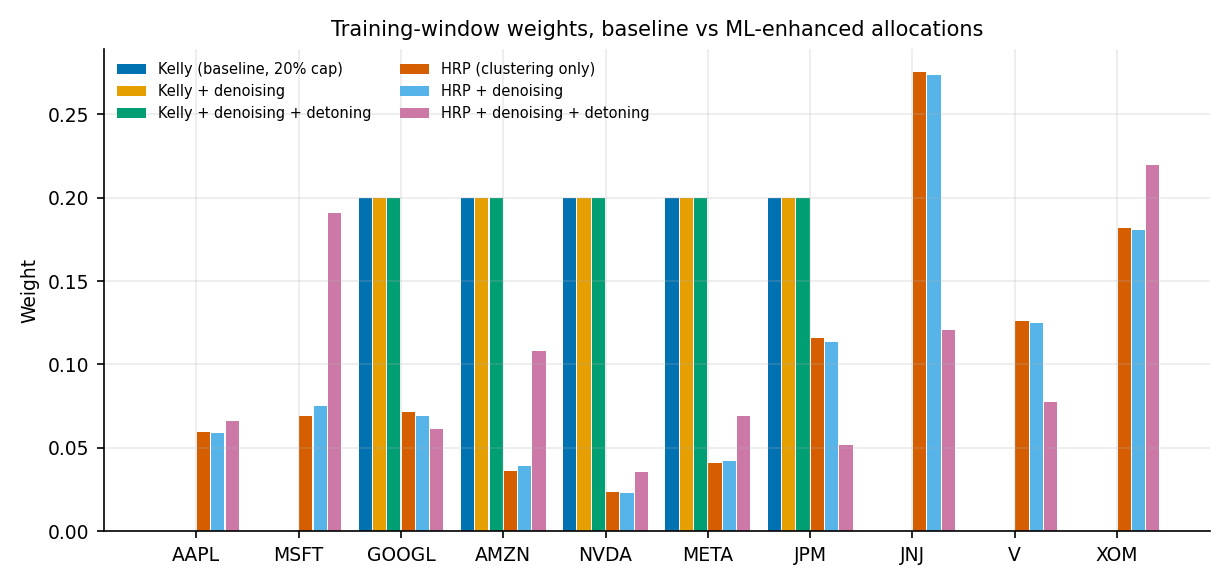

,"Kelly (baseline, 20% cap)",Kelly + denoising,Kelly + denoising + detoning,HRP (clustering only),HRP + denoising,HRP + denoising + detoning
AAPL,0.0,0.0,0.0,0.0593,0.0588,0.0662
MSFT,0.0,0.0,0.0,0.0693,0.0750,0.1909
GOOGL,0.2,0.2,0.2,0.0712,0.0691,0.0610
AMZN,0.2,0.2,0.2,0.0364,0.0394,0.1080
NVDA,0.2,0.2,0.2,0.0234,0.0227,0.0352
META,0.2,0.2,0.2,0.0408,0.0421,0.0692
JPM,0.2,0.2,0.2,0.1157,0.1133,0.0518
JNJ,0.0,0.0,0.0,0.2756,0.2736,0.1206
V,0.0,0.0,0.0,0.1261,0.1251,0.0773
XOM,0.0,0.0,0.0,0.1821,0.1808,0.2199


In [16]:
fig_weights(variants, OUT / "fig4_step5_weights.png")
display(Image(str(OUT / "fig4_step5_weights.png")))
pd.DataFrame(variants, index=TICKERS).round(4)

## Step 6: Do multiple improvements beat single ones out of sample?

The six allocations estimated on the training window are held fixed and evaluated on Q4 2025
using five metrics: cumulative return, Sharpe, Sortino, maximum drawdown and 95% cVaR.

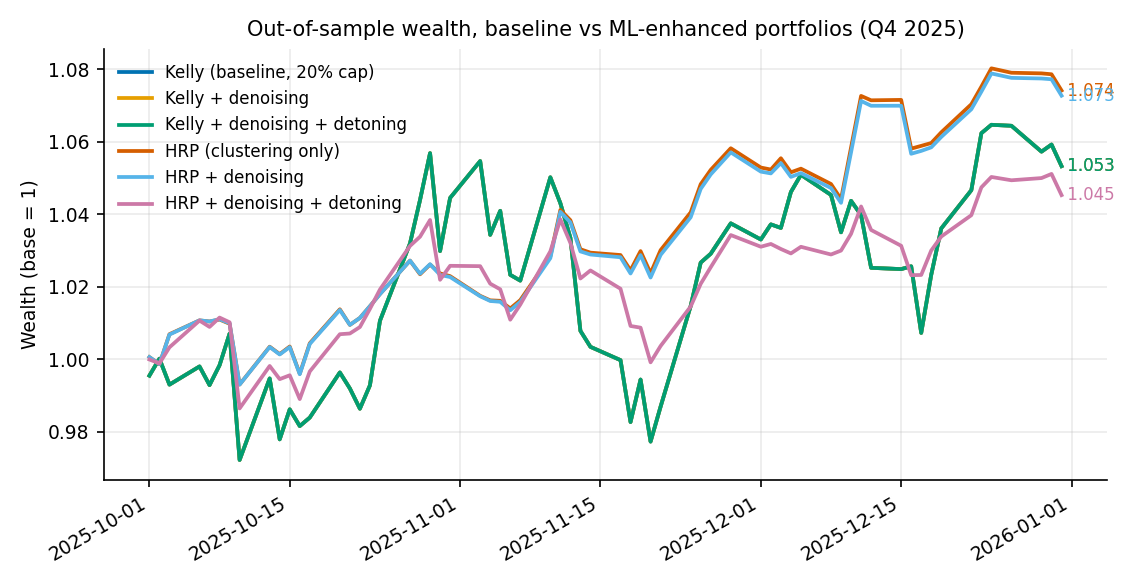

,cum_return,ann_return,ann_vol,sharpe,sortino,max_drawdown,cvar95
"Kelly (baseline, 20% cap)",0.0533,0.2249,0.2035,0.9083,1.3633,-0.0752,-0.0261
Kelly + denoising,0.0533,0.2249,0.2035,0.9083,1.3633,-0.0752,-0.0261
Kelly + denoising + detoning,0.0533,0.2249,0.2035,0.9083,1.3633,-0.0752,-0.0261
HRP (clustering only),0.0741,0.2860,0.0942,2.6116,4.2247,-0.0177,-0.0111
HRP + denoising,0.0727,0.2808,0.0939,2.5638,4.1388,-0.0178,-0.0111
HRP + denoising + detoning,0.0453,0.1801,0.1071,1.3085,1.6662,-0.0379,-0.0147


In [17]:
var_series = {n: portfolio_series(np.asarray(w), test) for n, w in variants.items()}
step6 = pd.DataFrame({n: metrics(s) for n, s in var_series.items()}).T
fig_wealth(var_series, OUT / "fig5_step6_wealth.png",
           "Out-of-sample wealth, baseline vs ML-enhanced portfolios (Q4 2025)")
display(Image(str(OUT / "fig5_step6_wealth.png")))
step6.round(4)

### Reading the results

Under the 20% cap, the Kelly solution is a **corner solution** with five names at the cap. Denoising
and detoning therefore leave the *constrained* weights, and with them the OOS metrics, unchanged.
The cap itself is the binding regulariser. Their effect shows up where one would expect it, on the
**unconstrained** problem: denoising cuts the gross exposure of the Kelly solution and improves the
conditioning of the correlation matrix.

**HRP** builds a very different, risk-balanced book (overweight JNJ, XOM and V). It beats every Kelly
variant on Sharpe, Sortino, drawdown and cVaR in Q4 2025, the price being a weaker return engine over
the training period.

**Detoning improved the Kelly diagnostics but hurt HRP this particular quarter.** Removing the market
component moved HRP's weights toward MSFT and away from the defensives that carried Q4. One quarter
cannot settle that question, which is exactly why the CPCV distribution of Step 3, and not a single OOS
window, should be the decision statistic.

